In [2]:
import numpy as np
import os
import matplotlib.pyplot as plt
import glob
import re
from collections import defaultdict
import matplotlib.gridspec as gridspec
import matplotlib.ticker as ticker
import polars as pl
from scipy.optimize import minimize
import joblib
from pathlib import Path
from sklearn.preprocessing import MinMaxScaler

In [3]:
mc_path = "Regions_MC_ver3"
data_path = "Regions_data_ver4"

mc_processes = ["Diboson", "Multijet", "Single_top", "ttbar", "Wjets", "Zjets"]

columns_to_load_mc = [
    "raw_weights", 
    "weight_sub",
    "met_recalc_pt", "met_recalc_phi",
    "ht",
    
    "signal_jet_pt", 
    "signal_jet_eta", 
    "signal_jet_phi", 
    
    "AnalysisLargeRJetsAuxDyn_pt", 
    "AnalysisLargeRJetsAuxDyn_eta", 
    "AnalysisLargeRJetsAuxDyn_phi", 
    "AnalysisLargeRJetsAuxDyn_Tau1_wta", 
    "AnalysisLargeRJetsAuxDyn_Tau2_wta", 
    "AnalysisLargeRJetsAuxDyn_Tau3_wta"
]


columns_to_load_data = [
    "met_recalc_pt", "met_recalc_phi",
    "ht",
    "signal_jet_pt", 
    "signal_jet_eta", 
    "signal_jet_phi", 

    "AnalysisLargeRJetsAuxDyn_pt", 
    "AnalysisLargeRJetsAuxDyn_eta", 
    "AnalysisLargeRJetsAuxDyn_phi", 
    "AnalysisLargeRJetsAuxDyn_Tau1_wta", 
    "AnalysisLargeRJetsAuxDyn_Tau2_wta", 
    "AnalysisLargeRJetsAuxDyn_Tau3_wta"
]

In [4]:
### --- Loading MC events --- ###
MC_ATLAS_CR0L_paths = glob.glob(os.path.join(mc_path, "ATLAS_CR_MJRR", "*.parquet"))
MC_ATLAS_CR1L_paths = glob.glob(os.path.join(mc_path, "ATLAS_CR_1L", "*.parquet"))
MC_ATLAS_CR1L1B_paths = glob.glob(os.path.join(mc_path, "ATLAS_CR_1L1B", "*.parquet"))
MC_ATLAS_CR2L_paths = glob.glob(os.path.join(mc_path, "ATLAS_CR_2L", "*.parquet"))

MC_ML_CR0L_paths = glob.glob(os.path.join(mc_path, "ML_CR_0L", "*.parquet"))
MC_ML_CR1L_paths = glob.glob(os.path.join(mc_path, "ML_CR_1L", "*.parquet"))
MC_ML_CR1L1B_paths = glob.glob(os.path.join(mc_path, "ML_CR_1L1B", "*.parquet"))
MC_ML_CR2L_paths = glob.glob(os.path.join(mc_path, "ML_CR_2L", "*.parquet"))

MC_SR_paths = glob.glob(os.path.join(mc_path, "SR", "*.parquet"))

### --- Loading data events --- ###
DATA_ATLAS_CR0L_paths = glob.glob(os.path.join(data_path, "ATLAS_CR_MJRR", "*.parquet"))
DATA_ATLAS_CR1L_paths = glob.glob(os.path.join(data_path, "ATLAS_CR_1L", "*.parquet"))
DATA_ATLAS_CR1L1B_paths = glob.glob(os.path.join(data_path, "ATLAS_CR_1L1B", "*.parquet"))
DATA_ATLAS_CR2L_paths = glob.glob(os.path.join(data_path, "ATLAS_CR_2L", "*.parquet"))

DATA_ML_CR0L_paths = glob.glob(os.path.join(data_path, "ML_CR_0L", "*.parquet"))
DATA_ML_CR1L_paths = glob.glob(os.path.join(data_path, "ML_CR_1L", "*.parquet"))
DATA_ML_CR1L1B_paths = glob.glob(os.path.join(data_path, "ML_CR_1L1B", "*.parquet"))
DATA_ML_CR2L_paths = glob.glob(os.path.join(data_path, "ML_CR_2L", "*.parquet"))

DATA_SR_paths = glob.glob(os.path.join(data_path, "SR_0L", "*.parquet"))

# Check that we loaded the paths correctly
if not (MC_ATLAS_CR0L_paths and MC_ATLAS_CR1L_paths and MC_ATLAS_CR1L1B_paths and MC_ATLAS_CR2L_paths and
        MC_ML_CR0L_paths and MC_ML_CR1L_paths and MC_ML_CR1L1B_paths and MC_ML_CR2L_paths and 
        MC_SR_paths):
    raise ValueError("Error: One or more MC paths are empty. Please check the paths.")

if not (DATA_ATLAS_CR0L_paths and DATA_ATLAS_CR1L_paths and DATA_ATLAS_CR1L1B_paths and DATA_ATLAS_CR2L_paths and 
        DATA_ML_CR0L_paths and DATA_ML_CR1L_paths and DATA_ML_CR1L1B_paths and DATA_ML_CR2L_paths and 
        DATA_SR_paths):
    raise ValueError("Error: One or more data paths are empty. Please check the paths.")
print("Paths loaded successfully!")

Paths loaded successfully!


In [5]:
df = pl.read_parquet(MC_ATLAS_CR1L_paths[0], columns=columns_to_load_mc)
print("Columns in the MC CR1L sample:", df.columns)

Columns in the MC CR1L sample: ['raw_weights', 'weight_sub', 'met_recalc_pt', 'met_recalc_phi', 'ht', 'signal_jet_pt', 'signal_jet_eta', 'signal_jet_phi', 'AnalysisLargeRJetsAuxDyn_pt', 'AnalysisLargeRJetsAuxDyn_eta', 'AnalysisLargeRJetsAuxDyn_phi', 'AnalysisLargeRJetsAuxDyn_Tau1_wta', 'AnalysisLargeRJetsAuxDyn_Tau2_wta', 'AnalysisLargeRJetsAuxDyn_Tau3_wta']


In [6]:
def calc_features(lf: pl.LazyFrame, is_MC) -> pl.LazyFrame:
    """
    Calculates Mjj and tau ratios using the cleaned Parquet features, 
    then discards all low-level vectors.
    """

    lf = lf.with_columns(
        j1_pt  = pl.col("signal_jet_pt").list.get(0),
        j2_pt  = pl.col("signal_jet_pt").list.get(1),
        j1_eta = pl.col("signal_jet_eta").list.get(0),
        j2_eta = pl.col("signal_jet_eta").list.get(1),
        j1_phi = pl.col("signal_jet_phi").list.get(0),
        j2_phi = pl.col("signal_jet_phi").list.get(1),

        lrj1_t1 = pl.col("AnalysisLargeRJetsAuxDyn_Tau1_wta").list.get(0),
        lrj1_t2 = pl.col("AnalysisLargeRJetsAuxDyn_Tau2_wta").list.get(0),
        lrj1_t3 = pl.col("AnalysisLargeRJetsAuxDyn_Tau3_wta").list.get(0),
        lrj2_t1 = pl.col("AnalysisLargeRJetsAuxDyn_Tau1_wta").list.get(1),
        lrj2_t2 = pl.col("AnalysisLargeRJetsAuxDyn_Tau2_wta").list.get(1),
        lrj2_t3 = pl.col("AnalysisLargeRJetsAuxDyn_Tau3_wta").list.get(1),
    )


    lf = lf.with_columns(
        mjj = (
            2 * pl.col("j1_pt") * pl.col("j2_pt") * ((pl.col("j1_eta") - pl.col("j2_eta")).cosh() - (pl.col("j1_phi") - pl.col("j2_phi")).cos())
        ).sqrt(),

        ljet1_tau21 = pl.when(pl.col("lrj1_t1") > 0).then(pl.col("lrj1_t2") / pl.col("lrj1_t1")).otherwise(0),
        ljet1_tau32 = pl.when(pl.col("lrj1_t2") > 0).then(pl.col("lrj1_t3") / pl.col("lrj1_t2")).otherwise(0),
        ljet2_tau21 = pl.when(pl.col("lrj2_t1") > 0).then(pl.col("lrj2_t2") / pl.col("lrj2_t1")).otherwise(0),
        ljet2_tau32 = pl.when(pl.col("lrj2_t2") > 0).then(pl.col("lrj2_t3") / pl.col("lrj2_t2")).otherwise(0),
    )

    if is_MC:
        final_columns = [
            "mc_process", "subprocess",                                              
            "raw_weights", 
            "weight_sub",
            "met_recalc_pt", "met_recalc_phi",                                       
            "ht", "mjj",                                                             # HT is native to the parquet now
            "ljet1_tau21", "ljet1_tau32", "ljet2_tau21", "ljet2_tau32"               
        ]
    else:
        final_columns = [                                                            
            "met_recalc_pt", "met_recalc_phi",                                       
            "ht", "mjj",                                                             
            "ljet1_tau21", "ljet1_tau32", "ljet2_tau21", "ljet2_tau32"               
        ]
        
    return lf.select(final_columns)

# def get_lazyframes(paths, is_mc):

#     files_by_meta = defaultdict(list)
#     known_processes = ['Wjets', 'Zjets', 'ttbar', 'Diboson', 'Multijet', 'Single_top']
    
#     for filepath in paths:
#         filename = os.path.basename(filepath)
        
#         if is_mc:
#             mc_process = next((p for p in known_processes if filename.startswith(p)), "Other")
#             name_no_ext = filename.replace(".parquet", "") 
#             if name_no_ext.startswith(mc_process + "_"):
#                 remainder = name_no_ext[len(mc_process) + 1:]
#             else:
#                 remainder = name_no_ext  
#             subprocess = re.sub(r"_batch\d+$", "", remainder) 
#             files_by_meta[(mc_process, subprocess)].append(filepath)
#         else:
#             files_by_meta[("Data", "Data")].append(filepath)

#     lazy_frames = []
#     for (mc_process, subprocess), group_paths in files_by_meta.items():
#         if is_mc:
#             lf = pl.scan_parquet(group_paths).select(columns_to_load_mc)
#             lf = lf.with_columns(
#                 pl.lit(mc_process).alias("mc_process"),
#                 pl.lit(subprocess).alias("subprocess")
#             )
#         else:
#             lf = pl.scan_parquet(group_paths).select(columns_to_load_data)
            
#         lf = calc_features(lf, is_mc)
#         lazy_frames.append(lf)

#     return lazy_frames

def get_lazyframes(paths, is_mc):
    files_by_meta = defaultdict(list)
    known_processes = ['Wjets', 'Zjets', 'ttbar', 'Diboson', 'Multijet', 'Single_top']
    
    for filepath in paths:
        filename = os.path.basename(filepath)
        
        if is_mc:
            mc_process = next((p for p in known_processes if filename.startswith(p)), "Other")
            name_no_ext = filename.replace(".parquet", "") 
            if name_no_ext.startswith(mc_process + "_"):
                remainder = name_no_ext[len(mc_process) + 1:]
            else:
                remainder = name_no_ext  
            subprocess = re.sub(r"_batch\d+$", "", remainder) 
            files_by_meta[(mc_process, subprocess)].append(filepath)
        else:
            files_by_meta[("Data", "Data")].append(filepath)

    lazy_frames = []
    for (mc_process, subprocess), group_paths in files_by_meta.items():
        # 1. Add aggressive parallelization to the parquet reader
        if is_mc:
            lf = pl.scan_parquet(group_paths, parallel="row_groups").select(columns_to_load_mc)
            lf = lf.with_columns(
                pl.lit(mc_process).alias("mc_process"),
                pl.lit(subprocess).alias("subprocess")
            )
        else:
            lf = pl.scan_parquet(group_paths, parallel="row_groups").select(columns_to_load_data)
            
        lf = calc_features(lf, is_mc)
        lazy_frames.append(lf)

    return lazy_frames

#### Process CR1L

In [7]:
MC_ATLAS_CR1L_lazy = get_lazyframes(MC_ATLAS_CR1L_paths, is_mc=True)
DATA_ATLAS_CR1L_lazy = get_lazyframes(DATA_ATLAS_CR1L_paths, is_mc=False)

MC_ATLAS_CR1L = pl.concat(MC_ATLAS_CR1L_lazy).collect(engine="streaming")
DATA_ATLAS_CR1L = pl.concat(DATA_ATLAS_CR1L_lazy).collect(engine="streaming")

#### Process CR1L1B

In [8]:
MC_ATLAS_CR1L1B_lazy = get_lazyframes(MC_ATLAS_CR1L1B_paths, is_mc=True)
DATA_ATLAS_CR1L1B_lazy = get_lazyframes(DATA_ATLAS_CR1L1B_paths, is_mc=False)

MC_ATLAS_CR1L1B = pl.concat(MC_ATLAS_CR1L1B_lazy).collect(engine="streaming")
DATA_ATLAS_CR1L1B = pl.concat(DATA_ATLAS_CR1L1B_lazy).collect(engine="streaming")

#### Process CR2L

In [9]:
MC_ATLAS_CR2L_lazy = get_lazyframes(MC_ATLAS_CR2L_paths, is_mc=True)
DATA_ATLAS_CR2L_lazy = get_lazyframes(DATA_ATLAS_CR2L_paths, is_mc=False)

MC_ATLAS_CR2L = pl.concat(MC_ATLAS_CR2L_lazy).collect(engine="streaming")
DATA_ATLAS_CR2L = pl.concat(DATA_ATLAS_CR2L_lazy).collect(engine="streaming")

#### Process CR0L

In [10]:
MC_ATLAS_CR0L_lazy = get_lazyframes(MC_ATLAS_CR0L_paths, is_mc=True)
DATA_ATLAS_CR0L_lazy = get_lazyframes(DATA_ATLAS_CR0L_paths, is_mc=False)

MC_ATLAS_CR0L = pl.concat(MC_ATLAS_CR0L_lazy).collect(engine="streaming")
DATA_ATLAS_CR0L = pl.concat(DATA_ATLAS_CR0L_lazy).collect(engine="streaming")

#### Process SR

In [11]:
MC_SR_lazy = get_lazyframes(MC_SR_paths, is_mc=True)
DATA_SR_lazy = get_lazyframes(DATA_SR_paths, is_mc=False)

MC_SR = pl.concat(MC_SR_lazy).collect(engine="streaming")
DATA_SR = pl.concat(DATA_SR_lazy).collect(engine="streaming")

In [12]:
meta_df = pl.read_csv("metadata_processed.csv").select([
    "physics_short", 
    "crossSection_pb", 
    "genFiltEff", 
    "kFactor",
    "sumOfWeights",
    "sum_w_pros", 
    "scale_factor_sub_weight", 
    "luminosity"
]).rename({"physics_short": "subprocess"})

def plot_mc_data_comparison(df_mc: pl.DataFrame, df_data: pl.DataFrame, region_name: str = ""):
    """
    Plots Data vs MC using native ATLAS scale factor calculations.
    Saves individual, thesis-ready PDFs for each variable with dynamic legend spacing,
    automatic log-scale handling, and MC Statistical uncertainty bands.
    """
    
    # Thesis/Publication styling settings
    plt.rcParams.update({
        'font.size': 14,
        'axes.labelsize': 16,
        'xtick.labelsize': 14,
        'ytick.labelsize': 14,
        'legend.fontsize': 12,
        'lines.linewidth': 1.5,
        'xtick.direction': 'in',
        'ytick.direction': 'in',
        'xtick.top': True,
        'ytick.right': True,
        'axes.formatter.use_mathtext': True,
        'axes.linewidth': 1.2,
        'hatch.linewidth': 0.5 # Thinner hatch lines look cleaner
    })
    
    variables = [
        'ht', 'met_recalc_pt', 'mjj', 
        'ljet1_tau21', 'ljet1_tau32', 'ljet2_tau21', 'ljet2_tau32'
    ]
    
    log_variables = ['ht', 'met_recalc_pt', 'mjj']
    mc_processes = ["Diboson", "Single_top", "ttbar", "Zjets", "Wjets", "Multijet"]
    
    color_map = {
        "Diboson": "#e31a1c", "Multijet": "#fdbf6f", "Single_top": "#ff7f00",
        "ttbar": "#cab2d6", "Wjets": "#33a02c", "Zjets": "#1f78b4"
    }
    
    pretty_labels = {
        'ht': r'$H_{T}$ [GeV]', 'met_recalc_pt': r'$E_{T}^{\text{miss}}$ [GeV]',
        'mjj': r'$m_{jj}$ [GeV]', 'ljet1_tau21': r'Leading jet $\tau_{21}$',
        'ljet1_tau32': r'Leading jet $\tau_{32}$', 'ljet2_tau21': r'Subleading jet $\tau_{21}$',
        'ljet2_tau32': r'Subleading jet $\tau_{32}$'
    }

    for branch in variables:
        valid_mc_df = df_mc.filter(pl.col(branch).is_not_null())
        valid_data_df = df_data.filter(pl.col(branch).is_not_null())
        
        valid_mc_arr = valid_mc_df.get_column(branch).to_numpy()
        valid_data_arr = valid_data_df.get_column(branch).to_numpy()
        
        if len(valid_mc_arr) == 0 and len(valid_data_arr) == 0:
            continue
            
        combined_data = np.concatenate([valid_mc_arr, valid_data_arr])
        bins = np.histogram_bin_edges(combined_data, bins=15)
        bin_centers = (bins[:-1] + bins[1:]) / 2
        bin_widths = np.diff(bins) 
        
        fig = plt.figure(figsize=(8, 8))
        gs = gridspec.GridSpec(2, 1, height_ratios=[3.5, 1], hspace=0.08)
        
        ax_main = fig.add_subplot(gs[0])
        ax_ratio = fig.add_subplot(gs[1], sharex=ax_main)
        
        mc_hists = []
        mc_weights = []
        labels = []
        
        for proc in mc_processes:
            proc_df = valid_mc_df.filter(pl.col('mc_process') == proc)
            if proc_df.height == 0: continue
                
            mc_hists.append(proc_df.get_column(branch).to_numpy())
            mc_weights.append(proc_df.get_column('final_weight').to_numpy())
            labels.append(proc)
            
        mc_colors = [color_map.get(l, '#999999') for l in labels]
        if mc_hists:
            ax_main.hist(
                mc_hists, bins=bins, weights=mc_weights, 
                stacked=True, label=labels, color=mc_colors, 
                histtype='stepfilled', edgecolor='black', linewidth=0.5
            )
        
        # --- MC STATISTICAL UNCERTAINTY ONLY ---
        mc_total_weights = valid_mc_df.get_column('final_weight').to_numpy() if 'final_weight' in valid_mc_df.columns else np.ones_like(valid_mc_arr)
        total_mc, _ = np.histogram(valid_mc_arr, bins=bins, weights=mc_total_weights)
        
        # Stat error: sum of squared weights per bin
        mc_stat_var, _ = np.histogram(valid_mc_arr, bins=bins, weights=mc_total_weights**2)
        mc_err = np.sqrt(mc_stat_var) # Just the stat error

        ax_main.bar(bin_centers, 2 * mc_err, bottom=total_mc - mc_err, width=bin_widths,
                    color='none', edgecolor='gray', hatch='////', linewidth=0,
                    alpha=0.5, zorder=5, label='Stat. Unc.')
        # ---------------------------------------

        counts_data, _ = np.histogram(valid_data_arr, bins=bins)
        ax_main.errorbar(
            bin_centers, counts_data, yerr=np.sqrt(counts_data), 
            fmt='ko', label='Data', zorder=10, capsize=0, markersize=5
        )
        
        max_data = np.max(counts_data) + np.max(np.sqrt(counts_data)) if len(counts_data) > 0 else 0
        max_mc = np.max(total_mc + mc_err) if len(total_mc) > 0 else 0 
        y_max = max(max_data, max_mc)
        
        if branch in log_variables:
            ax_main.set_yscale('log')
            ax_main.set_ylim(0.1, y_max * 1000)
        else:
            ax_main.set_ylim(0, y_max * 1.55) 
            ax_main.yaxis.set_minor_locator(ticker.AutoMinorLocator())
        
        ax_main.set_ylabel('Events / Bin')
        plt.setp(ax_main.get_xticklabels(), visible=False)
        ax_main.xaxis.set_minor_locator(ticker.AutoMinorLocator())
        
        if region_name:
            textstr = f"{region_name}\n" + r"$\sqrt{s} = 13$ TeV"
            ax_main.text(0.04, 0.94, textstr, transform=ax_main.transAxes,
                         fontsize=14, verticalalignment='top')

        handles, loc_labels = ax_main.get_legend_handles_labels()
        if "Data" in loc_labels:
            data_idx = loc_labels.index("Data")
            handles.insert(0, handles.pop(data_idx))
            loc_labels.insert(0, loc_labels.pop(data_idx))
            
        ax_main.legend(handles, loc_labels, loc='upper right', frameon=False, ncol=2)

        with np.errstate(divide='ignore', invalid='ignore'):
            ratio = counts_data / total_mc
            ratio_err = np.sqrt(counts_data) / total_mc
            ratio = np.where(total_mc > 0, ratio, np.nan)
            ratio_err = np.where(total_mc > 0, ratio_err, np.nan)

            rel_mc_err = np.where(total_mc > 0, mc_err / total_mc, 0)
        
        ax_ratio.bar(bin_centers, 2 * rel_mc_err, bottom=1.0 - rel_mc_err, width=bin_widths,
                     color='gray', hatch='////', edgecolor='none', alpha=0.3, zorder=1)
        
        ax_ratio.axhline(1, color='gray', linestyle='--', linewidth=1.0, zorder=2)
        ax_ratio.errorbar(bin_centers, ratio, yerr=ratio_err, fmt='ko', capsize=0, markersize=5, zorder=10)
        
        ax_ratio.set_ylabel('Data / MC')
        ax_ratio.set_xlabel(pretty_labels.get(branch, branch))
        ax_ratio.set_ylim(0.5, 1.5)
        ax_ratio.set_yticks([0.75, 1.0, 1.25])
        
        ax_ratio.xaxis.set_minor_locator(ticker.AutoMinorLocator())
        ax_ratio.yaxis.set_minor_locator(ticker.AutoMinorLocator())
        
        fig.align_ylabels((ax_main, ax_ratio))
        
        filename_region = f"_{region_name.replace(' ', '_')}" if region_name else ""
        save_name = f"data_mc_{branch}{filename_region}.pdf"
        # plt.savefig(f"Kinematic_Plots/{save_name}")
        plt.show()
        plt.close(fig)

def plot_subprocess_data_comparison(df_mc: pl.DataFrame, df_data: pl.DataFrame, region_name: str = ""):
    """
    Plots Data vs MC using native ATLAS scale factor calculations, stacked by subprocess.
    """
    variables = [
        'ht', 'met_recalc_pt', 'mjj', 
        'ljet1_tau21', 'ljet1_tau32', 'ljet2_tau21', 'ljet2_tau32'
    ]
    var_names = {
        "ht": "H_{T} [GeV]",
        "met_recalc_pt": "E_{T}^{miss} [GeV]",
        "mjj": "m_{jj} [GeV]",
        "ljet1_tau21": "Leading Jet #tau_{21}",
        "ljet1_tau32": "Leading Jet #tau_{32}",
        "ljet2_tau21": "Subleading Jet #tau_{21}",
        "ljet2_tau32": "Subleading Jet #tau_{32}"
    }

    sub_processes = df_mc.get_column("subprocess").drop_nulls().unique().to_list()
    sub_processes.sort() 
    n_procs = len(sub_processes)
    
    if n_procs <= 10:
        palette = plt.cm.tab10.colors[:n_procs]
    elif n_procs <= 20:
        indices = list(range(0, 20, 2)) + list(range(1, 20, 2))
        palette = [plt.cm.tab20.colors[i] for i in indices[:n_procs]]
    
    else:
        base_colors = plt.cm.nipy_spectral(np.linspace(0.05, 0.95, n_procs))
        rng = np.random.default_rng(seed=2218)
        palette = rng.permutation(base_colors)
        

    color_dict = {proc: color for proc, color in zip(sub_processes, palette)}
    
    fig = plt.figure(figsize=(24, 14))
    if region_name:
        fig.suptitle(f"{region_name}", fontsize=20, fontweight='bold')
    
    gs = gridspec.GridSpec(4, 10, height_ratios=[3, 1, 3, 1], hspace=0.3, wspace=0.4)
    
    def get_axes(idx):
        if idx < 2:
            col_start = idx * 5
            col_end = col_start + 5
            ax_main = fig.add_subplot(gs[0, col_start:col_end])
            ax_ratio = fig.add_subplot(gs[1, col_start:col_end], sharex=ax_main)
        else:
            idx_offset = idx - 2
            col_start = idx_offset * 2
            col_end = col_start + 2
            ax_main = fig.add_subplot(gs[2, col_start:col_end])
            ax_ratio = fig.add_subplot(gs[3, col_start:col_end], sharex=ax_main)
        return ax_main, ax_ratio

    global_handles = []
    global_labels = []

    for i, branch in enumerate(variables):
        ax_main, ax_ratio = get_axes(i)
        
        valid_mc_df = df_mc.filter(pl.col(branch).is_not_null())
        valid_data_df = df_data.filter(pl.col(branch).is_not_null())
        
        valid_mc_arr = valid_mc_df.get_column(branch).to_numpy()
        valid_data_arr = valid_data_df.get_column(branch).to_numpy()
        
        if len(valid_mc_arr) == 0 and len(valid_data_arr) == 0:
            continue
            
        combined_data = np.concatenate([valid_mc_arr, valid_data_arr])
        bins = np.histogram_bin_edges(combined_data, bins=15)
        bin_centers = (bins[:-1] + bins[1:]) / 2
        
        mc_hists = []
        mc_weights = []
        mc_colors = [] 
        labels = []
        
        for proc in sub_processes:
            proc_df = valid_mc_df.filter(pl.col('subprocess') == proc)
            data_proc = proc_df.get_column(branch).to_numpy()
            weights_proc = proc_df.get_column('final_weight').to_numpy()
            
            if len(data_proc) > 0:
                mc_hists.append(data_proc)
                mc_weights.append(weights_proc)
                labels.append(str(proc))
                mc_colors.append(color_dict[proc]) # Grab the mapped color
        
        if mc_hists:

            counts_mc, _, _ = ax_main.hist(
                mc_hists, bins=bins, weights=mc_weights, 
                stacked=True, label=labels, color=mc_colors,
                histtype='stepfilled', edgecolor='black', linewidth=0.5
            )
        else:
            counts_mc = [np.zeros_like(bin_centers)]
            
        counts_data, _ = np.histogram(valid_data_arr, bins=bins)
        ax_main.errorbar(
            bin_centers, counts_data, yerr=np.sqrt(counts_data), 
            fmt='ko', label='Data'
        )
        
        ax_main.set_ylabel('Events')
        ax_main.set_title(f"Distribution of {branch}", fontsize=14)
        
        if i == 0:
            global_handles, global_labels = ax_main.get_legend_handles_labels()
            
        total_mc = counts_mc[-1] if len(mc_hists) > 0 else np.zeros_like(counts_data)
        
        with np.errstate(divide='ignore', invalid='ignore'):
            ratio = counts_data / total_mc
            ratio_err = np.sqrt(counts_data) / total_mc
            ratio = np.where(total_mc > 0, ratio, np.nan)
            ratio_err = np.where(total_mc > 0, ratio_err, np.nan)
            
        ax_ratio.errorbar(bin_centers, ratio, yerr=ratio_err, fmt='ko')
        ax_ratio.axhline(1, color='gray', linestyle='--')
        ax_ratio.set_ylabel('Data / MC')
        ax_ratio.set_xlabel(branch)
        ax_ratio.set_ylim(0.5, 1.5) 
        plt.setp(ax_main.get_xticklabels(), visible=False)

    fig.subplots_adjust(top=0.92, bottom=0.08, left=0.05, right=0.82) 
    
    fig.legend(
        global_handles, 
        global_labels, 
        loc='center left', 
        bbox_to_anchor=(0.83, 0.5), 
        frameon=False, 
        title="Subprocesses",
        title_fontsize='x-large',
        fontsize=10,
        ncol=1 
    )

    plt.show()

In [13]:
def apply_intial_weights(df_mc: pl.DataFrame, meta_df: pl.DataFrame) -> pl.DataFrame:
    df_mc = df_mc.join(meta_df, on="subprocess", how="left")

    LUMI = 25.289004522843967
    
    df_mc = df_mc.with_columns(
        official_scale_factor = (
            pl.col("crossSection_pb") * LUMI * 1000 * pl.col("genFiltEff") * pl.col("kFactor")
        ) / pl.col("sum_w_pros")
    )

    return df_mc.with_columns(
        final_weight = pl.col("official_scale_factor") * pl.col("raw_weights")
    )

(array([70322., 66650., 63631., 60504., 57876., 55453., 53171., 50652.,
        48943., 46669.]),
 array([250.00001526, 255.        , 260.        , 265.        ,
        270.        , 274.99996948, 279.99996948, 284.99996948,
        289.99993896, 294.99993896, 299.99993896]),
 <BarContainer object of 10 artists>)

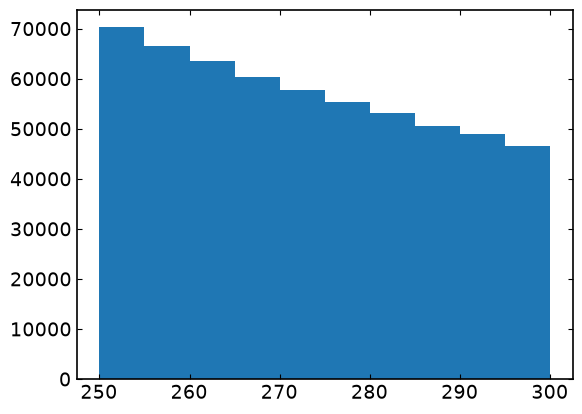

In [35]:
plt.hist(MC_ATLAS_CR0L["met_recalc_pt"])

(array([79385., 72910., 67830., 63031., 58558., 54719., 51251., 47662.,
        44629., 41867.]),
 array([250.00003052, 255.00003052, 260.00003052, 265.00003052,
        270.00003052, 275.        , 280.        , 285.        ,
        290.        , 295.        , 300.        ]),
 <BarContainer object of 10 artists>)

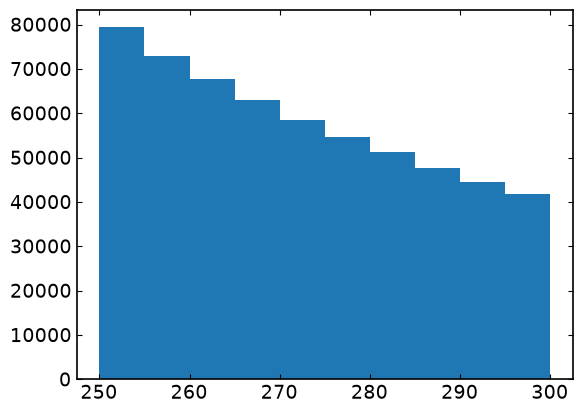

In [36]:
plt.hist(DATA_ATLAS_CR0L["met_recalc_pt"])

In [38]:
MC_ATLAS_CR0L_final = MC_ATLAS_CR0L.filter(
    (pl.col("met_recalc_pt") > 300)
)
DATA_ATLAS_CR0L_final = DATA_ATLAS_CR0L.filter(
    (pl.col("met_recalc_pt") > 300)
)

MC_SR_clean = MC_SR.filter(
    (pl.col("ht") > 600) &
    (pl.col("met_recalc_pt") > 600) &
    (pl.col("met_recalc_pt") < 2000) & 
    (pl.col("mjj") < 10000) & 
    (pl.col("ht") < 4000)
)
DATA_SR_clean = DATA_SR.filter(
    (pl.col("ht") > 600) &
    (pl.col("met_recalc_pt") > 600) &
    (pl.col("met_recalc_pt") < 2000) & 
    (pl.col("mjj") < 10000) & 
    (pl.col("ht") < 4000)
)

In [40]:
MC_ATLAS_CR0L_final_w1 = apply_intial_weights(MC_ATLAS_CR0L_final, meta_df)
MC_ATLAS_CR1L_w1 = apply_intial_weights(MC_ATLAS_CR1L, meta_df)
MC_ATLAS_CR1L1B_w1 = apply_intial_weights(MC_ATLAS_CR1L1B, meta_df)
MC_ATLAS_CR2L_w1 = apply_intial_weights(MC_ATLAS_CR2L, meta_df)

MC_SR_clean_w1 = apply_intial_weights(MC_SR_clean, meta_df)   

In [41]:
procs_to_remove = ["Pythia8EvtGen_A14NNPDF23LO_jetjet_JZ0WithSW"]
MC_ATLAS_CR1L_f = MC_ATLAS_CR1L_w1.filter(~pl.col("subprocess").is_in(procs_to_remove))
MC_ATLAS_CR1L1B_f = MC_ATLAS_CR1L1B_w1.filter(~pl.col("subprocess").is_in(procs_to_remove))
MC_ATLAS_CR2L_f = MC_ATLAS_CR2L_w1.filter(~pl.col("subprocess").is_in(procs_to_remove))
MC_ATLAS_CR0L_final_f = MC_ATLAS_CR0L_final_w1.filter(~pl.col("subprocess").is_in(procs_to_remove))
MC_SR_clean_f = MC_SR_clean_w1.filter(~pl.col("subprocess").is_in(procs_to_remove))  

In [42]:
MC_ATLAS_TOTAL_CR_df_before = pl.concat([
    MC_ATLAS_CR0L_final_f, 
    MC_ATLAS_CR1L_f, 
    MC_ATLAS_CR1L1B_f, 
    MC_ATLAS_CR2L_f
])
DATA_ATLAS_TOTAL_CR_df_before = pl.concat([
    DATA_ATLAS_CR0L_final, 
    DATA_ATLAS_CR1L, 
    DATA_ATLAS_CR1L1B, 
    DATA_ATLAS_CR2L
])

In [43]:
sum(MC_ATLAS_TOTAL_CR_df_before["final_weight"])

109500.63119048245

In [44]:
def calculate_fitted_lumi(df_mc: pl.DataFrame, df_data: pl.DataFrame, current_lumi: float) -> float:

    total_mc_yield = df_mc.select(pl.col("final_weight").sum()).item()
    
    total_data_yield = df_data.height 

    scale_factor = total_data_yield / total_mc_yield

    fitted_lumi = current_lumi * scale_factor
    
    print(f"Total Data: {total_data_yield}")
    print(f"Total MC:   {total_mc_yield:.2f}")
    print(f"Correction: {scale_factor:.4f}")
    print(f"Fitted Lumi: {fitted_lumi:.4f}")
    
    return fitted_lumi

# Usage:
OLD_LUMI = 25.289004522843967
new_lumi_ATLAS = calculate_fitted_lumi(MC_ATLAS_TOTAL_CR_df_before, DATA_ATLAS_TOTAL_CR_df_before, OLD_LUMI)

Total Data: 109913
Total MC:   109500.63
Correction: 1.0038
Fitted Lumi: 25.3842


In [45]:
def apply_final_weights(df_mc: pl.DataFrame, meta_df: pl.DataFrame, new_lumi) -> pl.DataFrame:
    df_mc = df_mc.join(meta_df, on="subprocess", how="left")

    # LUMI = 25.3845 

    df_mc = df_mc.with_columns(
        official_scale_factor = (
            pl.col("crossSection_pb") * new_lumi * 1000 * pl.col("genFiltEff") * pl.col("kFactor")
        ) / pl.col("sum_w_pros")
    )

    return df_mc.with_columns(
        final_weight = pl.col("official_scale_factor") * pl.col("raw_weights")
    )

In [46]:
MC_ATLAS_CR1L_w = apply_final_weights(MC_ATLAS_CR1L_f, meta_df, new_lumi_ATLAS)
MC_ATLAS_CR1L1B_w = apply_final_weights(MC_ATLAS_CR1L1B_f, meta_df, new_lumi_ATLAS)
MC_ATLAS_CR2L_w = apply_final_weights(MC_ATLAS_CR2L_f, meta_df, new_lumi_ATLAS)
MC_ATLAS_CR0L_w = apply_final_weights(MC_ATLAS_CR0L_final_f, meta_df, new_lumi_ATLAS)
MC_SR_w = apply_final_weights(MC_SR_clean_f, meta_df, new_lumi_ATLAS)

In [59]:
DATA_ATLAS_TOTAL_CR_df = pl.concat([
    DATA_ATLAS_CR0L_final, 
    DATA_ATLAS_CR1L, 
    DATA_ATLAS_CR1L1B, 
    DATA_ATLAS_CR2L
])

MC_ATLAS_TOTAL_CR_df = pl.concat([
    MC_ATLAS_CR0L_w, 
    MC_ATLAS_CR1L_w, 
    MC_ATLAS_CR1L1B_w, 
    MC_ATLAS_CR2L_w
])


In [60]:
len(DATA_ATLAS_TOTAL_CR_df)

109913

In [61]:
sum(MC_ATLAS_TOTAL_CR_df["final_weight"])

109912.99999999999

In [62]:
DATA_ATLAS_TOTAL_CR_df

met_recalc_pt,met_recalc_phi,ht,mjj,ljet1_tau21,ljet1_tau32,ljet2_tau21,ljet2_tau32
f32,f32,f32,f32,f32,f32,f32,f32
614.797241,-2.105824,713.625671,366.795258,0.419549,0.667866,0.47721,0.648152
705.961426,0.509834,944.192261,801.067871,0.347322,0.514066,0.474306,0.755335
651.845825,-2.825912,1179.018921,1285.476929,0.164965,0.794131,0.503172,0.547512
782.820679,-2.86112,873.392639,420.538635,0.682232,0.714377,0.489055,0.799055
706.586853,1.386036,835.115356,289.630127,0.266555,0.663307,0.434452,0.757797
…,…,…,…,…,…,…,…
676.67395,2.838848,849.461426,400.118225,0.76502,0.797044,0.636833,0.658531
833.177307,1.947774,1255.793457,830.419556,0.674922,0.747022,0.524397,0.681008
1449.625854,0.314956,1608.486694,889.889709,0.644785,0.533457,0.429592,0.760606


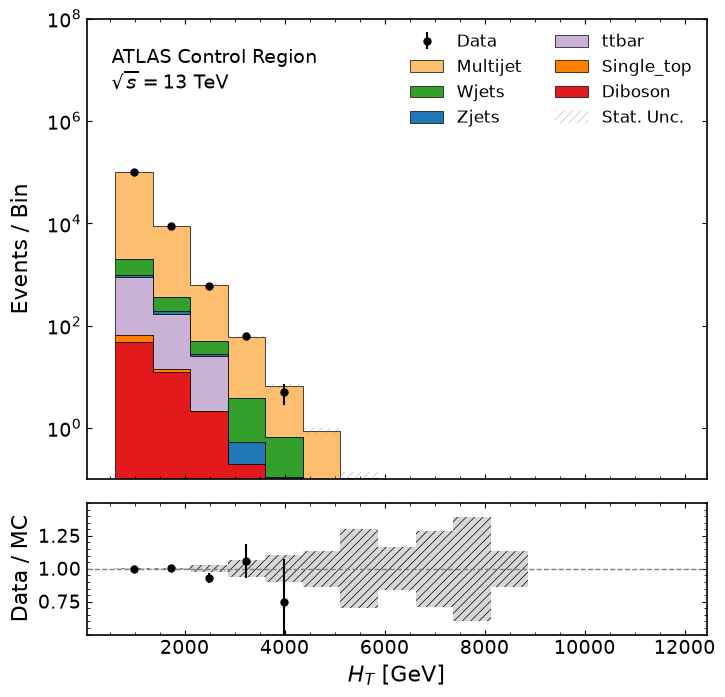

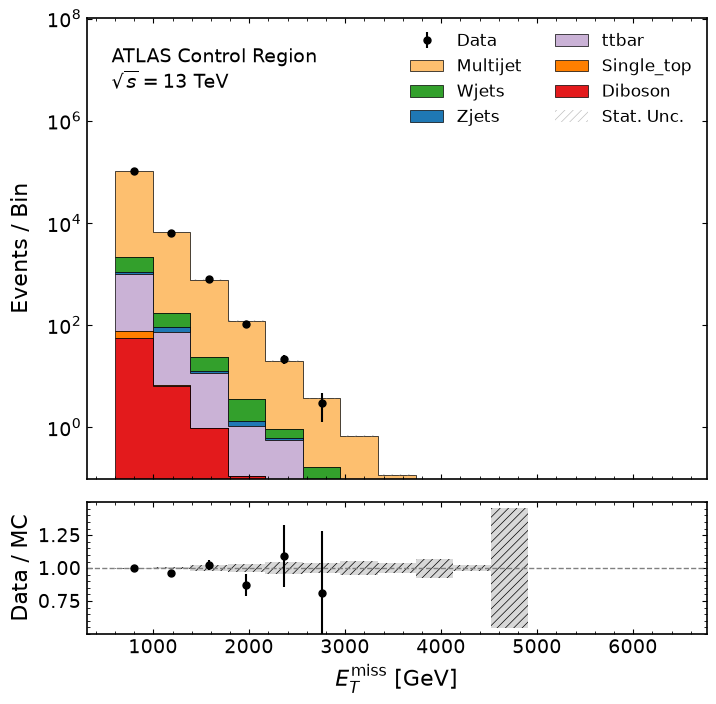

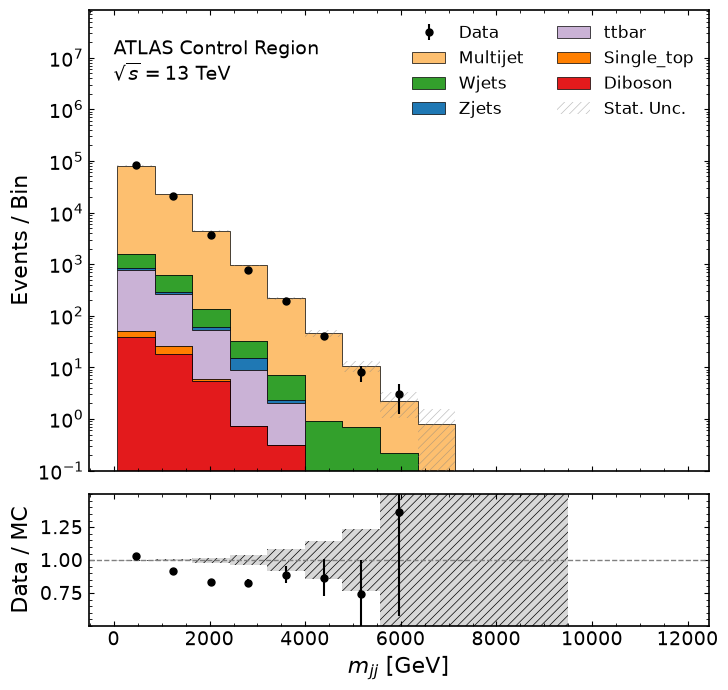

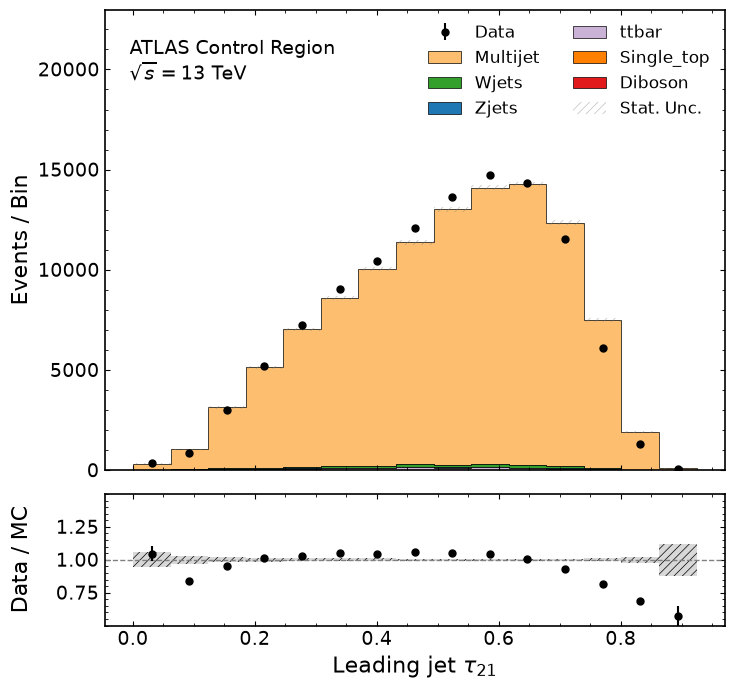

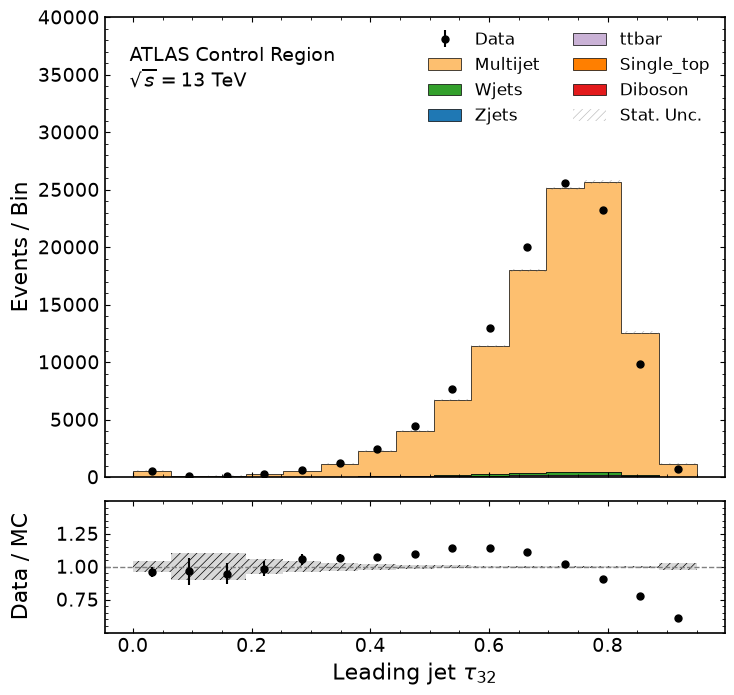

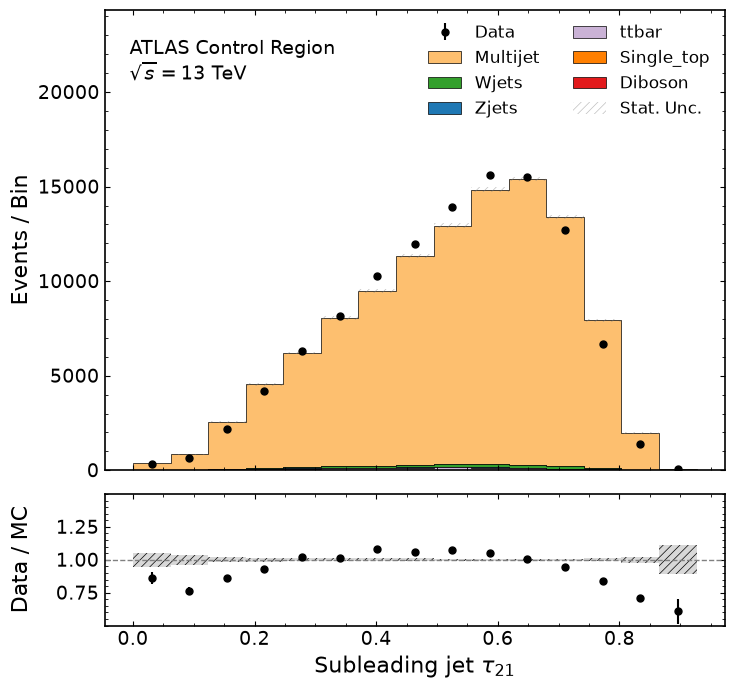

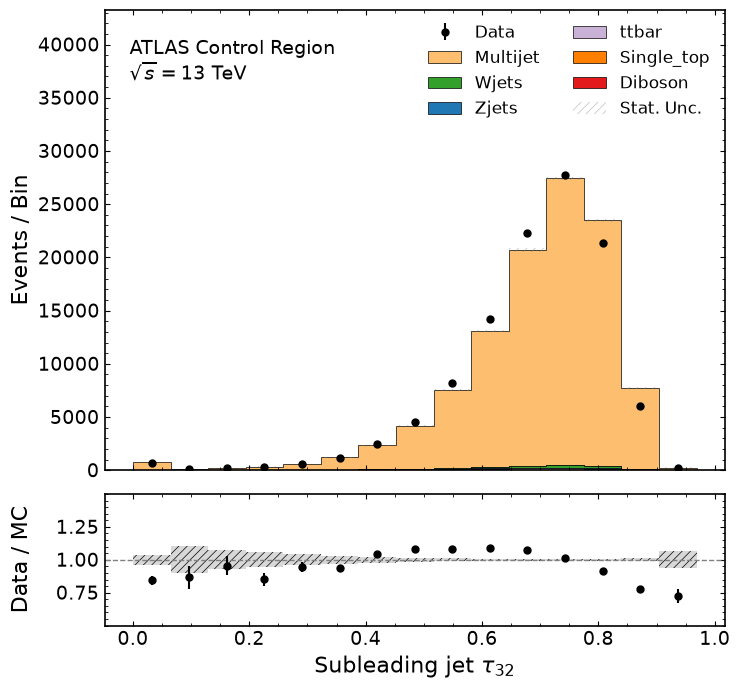

In [55]:
plot_mc_data_comparison(MC_ATLAS_TOTAL_CR_df, DATA_ATLAS_TOTAL_CR_df, "ATLAS Control Region")

### Split and Scale Samples

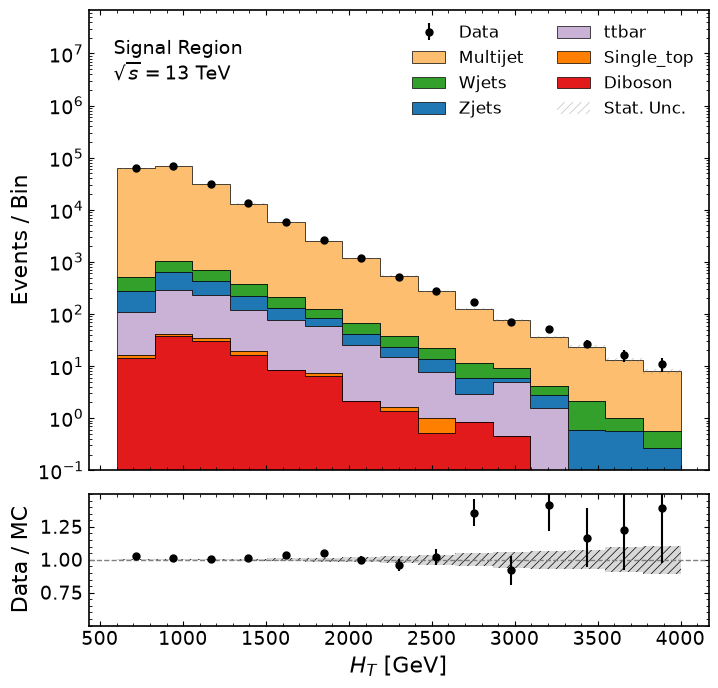

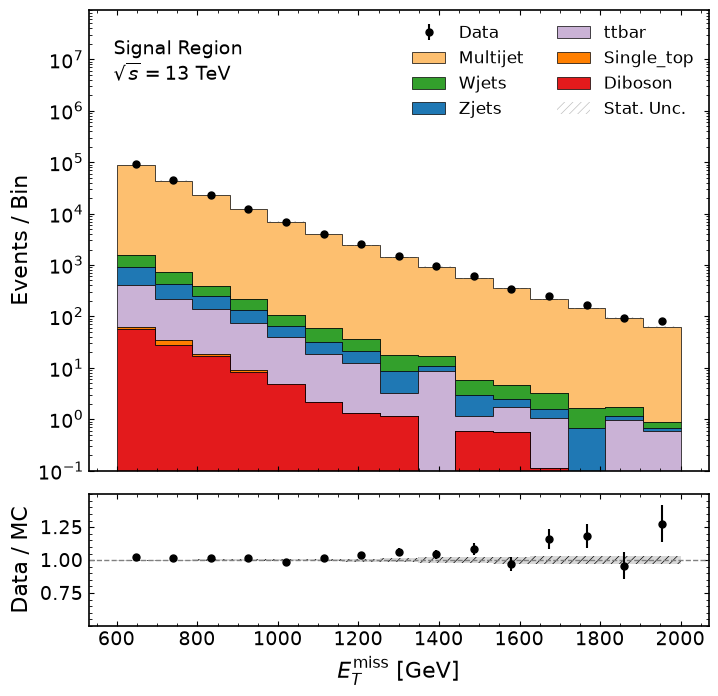

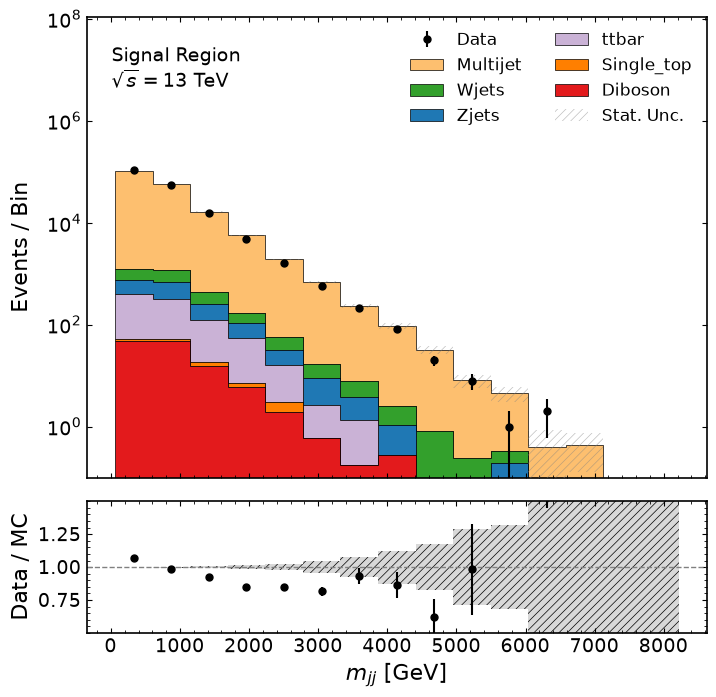

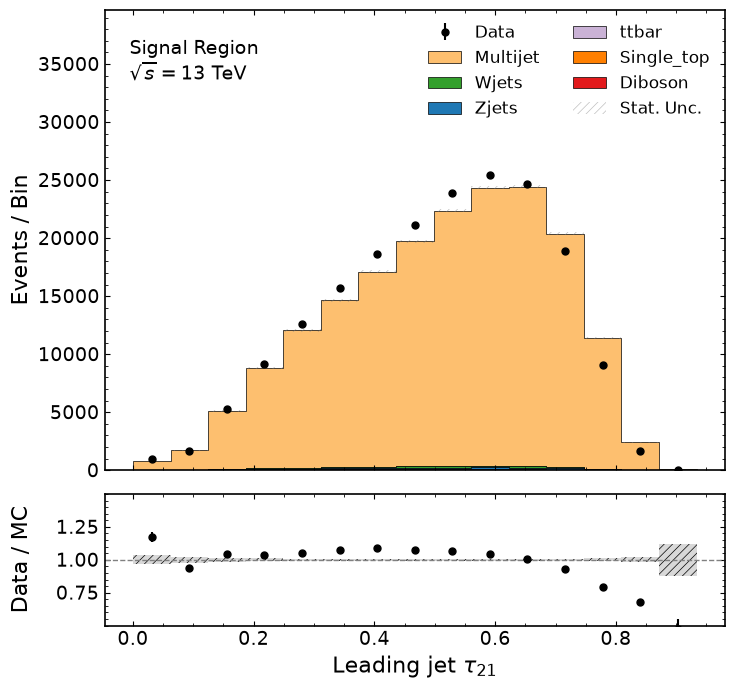

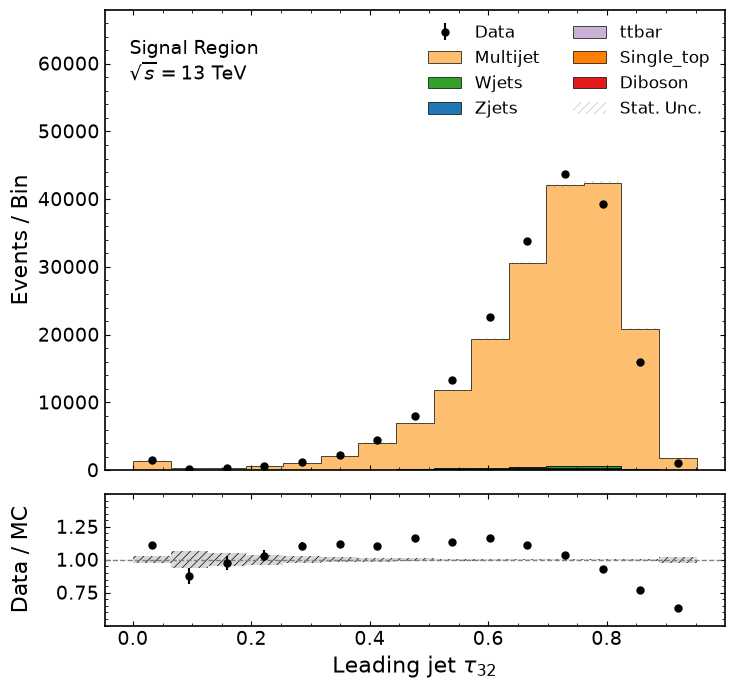

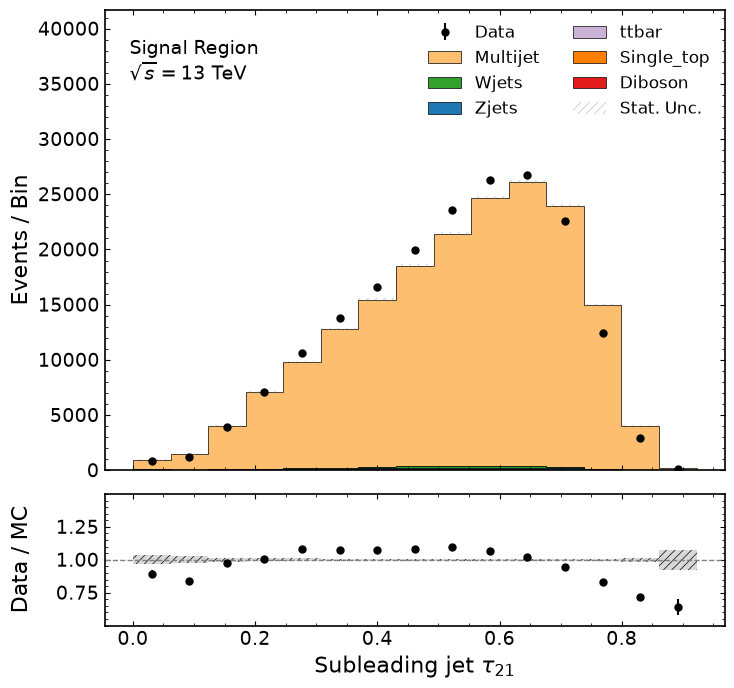

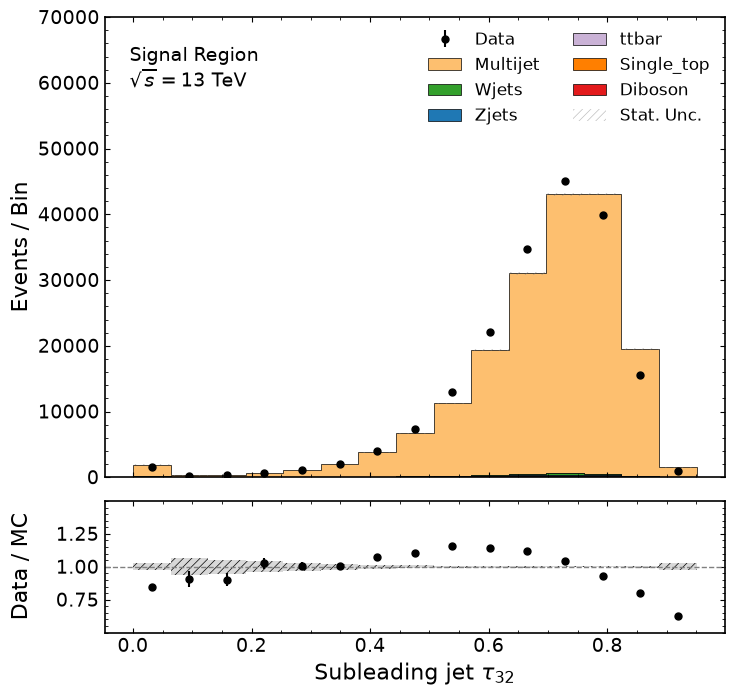

In [56]:
plot_mc_data_comparison(MC_SR_w, DATA_SR_clean, "Signal Region")

In [63]:
print(len(DATA_ATLAS_CR1L))
print(len(DATA_ATLAS_CR1L1B))
print(len(DATA_ATLAS_CR2L))
print(len(DATA_ATLAS_CR0L_final))


print("===")
print(len(DATA_ATLAS_TOTAL_CR_df))
print(len(DATA_ATLAS_CR1L) + len(DATA_ATLAS_CR1L1B) + len(DATA_ATLAS_CR2L) + len(DATA_ATLAS_CR0L_final))

88621
21148
144
0
===
109913
109913


In [64]:
output_dir = Path("Final_Dataset_ATLAS")
output_dir.mkdir(parents=True, exist_ok=True)

features_to_scale = [
    'met_recalc_pt', 'ht', 
    'mjj', 'ljet1_tau21', 'ljet1_tau32', 'ljet2_tau21', 'ljet2_tau32'
]

mc_datasets = {
    "MC_CR1L": MC_ATLAS_CR1L_w,
    "MC_CR1L1B": MC_ATLAS_CR1L1B_w,
    "MC_CR2L": MC_ATLAS_CR2L_w,
    "MC_CR0L": MC_ATLAS_CR0L_w,
    "MC_SR_clean": MC_SR_w
}


data_datasets = {
    "DATA_CR1L": DATA_ATLAS_CR1L,
    "DATA_CR1L1B": DATA_ATLAS_CR1L1B,
    "DATA_CR2L": DATA_ATLAS_CR2L,
    "DATA_CR0L": DATA_ATLAS_CR0L_final,
    "DATA_SR_clean": DATA_SR_clean
}

print("="*85)
print(" 📊 DATASET STATISTICS (BEFORE SCALING)")
print("="*85)

all_mc_features = []

for name in mc_datasets.keys():
    region = name.replace("MC_", "")
    df_mc = mc_datasets[name]
    df_data = data_datasets.get(f"DATA_{region}")
    
    n_data = df_data.height if df_data is not None else 0
    
    print(f"\nREGION: {region}")
    print(f"Total Data Events: {n_data}")
    print("-" * 85)
    print(f"{'Process':<15} | {'Subprocess':<35} | {'MC Events':<10} | {'MC Yield (SumW)':<15}")
    print("-" * 85)
    
    if df_mc is not None and df_mc.height > 0:

        weight_col = "final_weight"

        mc_stats = (
            df_mc.group_by(["mc_process", "subprocess"])
            .agg([
                pl.len().alias("count"),
                pl.col(weight_col).sum().alias("yield")
            ])
            .sort(["mc_process", "subprocess"])
        )

        for row in mc_stats.iter_rows(named=True):
            print(f"{row['mc_process']:<15} | {row['subprocess']:<35} | {row['count']:<10} | {row['yield']:<15.2f}")

        all_mc_features.append(df_mc.select(features_to_scale))
    else:
        print("No MC data found for this region.")

print("\n--- Global MC Boundaries (Across All Regions) ---")

df_all_mc = pl.concat(all_mc_features)
X_all_mc = df_all_mc.to_numpy()

print(f"{'Feature':<15} | {'Global Min':<12} | {'Global Max':<12}")
print("-" * 45)
for i, f in enumerate(features_to_scale):
    f_min = X_all_mc[:, i].min()
    f_max = X_all_mc[:, i].max()
    print(f"{f:<15} | {f_min:<12.2f} | {f_max:<12.2f}")
print("="*85 + "\n")
print("Fitting MinMaxScaler on combined MC...")

scaler = MinMaxScaler(feature_range=(-2.5, 2.5))
scaler.fit(X_all_mc)

scaler_path = output_dir / "minmax_scaler.joblib"
joblib.dump(scaler, scaler_path)
print(f"Scaler successfully saved to {scaler_path}\n")

def scale_dataframe(df: pl.DataFrame, fitted_scaler: MinMaxScaler, features: list) -> pl.DataFrame:
    """
    Extracts features, scales them using the fitted sklearn scaler, clips outliers,
    and safely overwrites the columns in the Polars DataFrame.
    """
    X_raw = df.select(features).to_numpy()

    X_scaled = fitted_scaler.transform(X_raw)

    scaled_series = [pl.Series(name=f, values=X_scaled[:, i]) for i, f in enumerate(features)]
    
    return df.with_columns(scaled_series)

print("Applying scaler to all MC and Data regions and saving to Parquet...")

all_datasets = {**mc_datasets, **data_datasets}

for name, df in all_datasets.items():
    if df is None or df.height == 0:
        print(f"Skipping {name}: DataFrame is empty or missing.")
        continue

    scaled_df = scale_dataframe(df, scaler, features_to_scale)

    file_path = output_dir / f"{name}.parquet"
    scaled_df.write_parquet(file_path)
    
    print(f"Saved: {file_path} (Shape: {scaled_df.shape})")

print("\nPipeline complete! All data scaled and ready for PyTorch.")

 📊 DATASET STATISTICS (BEFORE SCALING)

REGION: CR1L
Total Data Events: 88621
-------------------------------------------------------------------------------------
Process         | Subprocess                          | MC Events  | MC Yield (SumW)
-------------------------------------------------------------------------------------
Diboson         | Sh_2211_WlvWqq                      | 567        | 34.67          
Diboson         | Sh_2211_WlvZqq                      | 202        | 14.63          
Diboson         | Sh_2211_WqqZvv                      | 53         | 3.02           
Diboson         | Sh_2211_ZqqZvv                      | 12         | 0.77           
Multijet        | Pythia8EvtGen_A14NNPDF23LO_jetjet_JZ10WithSW | 10077      | 0.01           
Multijet        | Pythia8EvtGen_A14NNPDF23LO_jetjet_JZ11WithSW | 4693       | 0.00           
Multijet        | Pythia8EvtGen_A14NNPDF23LO_jetjet_JZ12WithSW | 5370       | 0.00           
Multijet        | Pythia8EvtGen_A14NNPDF23L